Step-1 Import required libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

import os
print(os.listdir())

import warnings
warnings.filterwarnings('ignore')

['heart.csv', 'Heart_Disease_Prediction.ipynb']


Step-2 Load and explore the dataset

In [4]:
dataset = pd.read_csv("heart.csv")
print(type(dataset))
print(dataset.shape)
print(dataset.head(5))
print(dataset.sample(5))
print(dataset.describe())
print(dataset.info())

<class 'pandas.DataFrame'>
(303, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  
     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
272   67    1   0       120   237    0        1       71      0      1.0   
257   50    1   0       144   200    0        0      126      1      0.9   
197   67    1   0       125   254    1        1      163      0      0.2   
298   57    0   0       140   241    0  

Understanding the columns

In [5]:
info = ["age","1: male, 0: female","chest pain type, 1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic","resting blood pressure"," serum cholestoral in mg/dl","fasting blood sugar > 120 mg/dl","resting electrocardiographic results (values 0,1,2)"," maximum heart rate achieved","exercise induced angina","oldpeak = ST depression induced by exercise relative to rest","the slope of the peak exercise ST segment","number of major vessels (0-3) colored by flourosopy","thal: 3 = normal; 6 = fixed defect; 7 = reversable defect"]

for i in range(len(info)):
    print(dataset.columns[i]+":\t\t\t"+info[i])

age:			age
sex:			1: male, 0: female
cp:			chest pain type, 1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic
trestbps:			resting blood pressure
chol:			 serum cholestoral in mg/dl
fbs:			fasting blood sugar > 120 mg/dl
restecg:			resting electrocardiographic results (values 0,1,2)
thalach:			 maximum heart rate achieved
exang:			exercise induced angina
oldpeak:			oldpeak = ST depression induced by exercise relative to rest
slope:			the slope of the peak exercise ST segment
ca:			number of major vessels (0-3) colored by flourosopy
thal:			thal: 3 = normal; 6 = fixed defect; 7 = reversable defect


Analysing the 'target' variable

In [6]:
print(dataset["target"].describe())
print(dataset["target"].unique())

count    303.000000
mean       0.544554
std        0.498835
min        0.000000
25%        0.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: target, dtype: float64
[1 0]


Step - 3 Checking correlation between columns

In [7]:
print(dataset.corr()["target"].abs().sort_values(ascending=False))

target      1.000000
exang       0.436757
cp          0.433798
oldpeak     0.430696
thalach     0.421741
ca          0.391724
slope       0.345877
thal        0.344029
sex         0.280937
age         0.225439
trestbps    0.144931
restecg     0.137230
chol        0.085239
fbs         0.028046
Name: target, dtype: float64


Step - 4 Exploratory Data Analysis (EDA)

Analysing the target variable

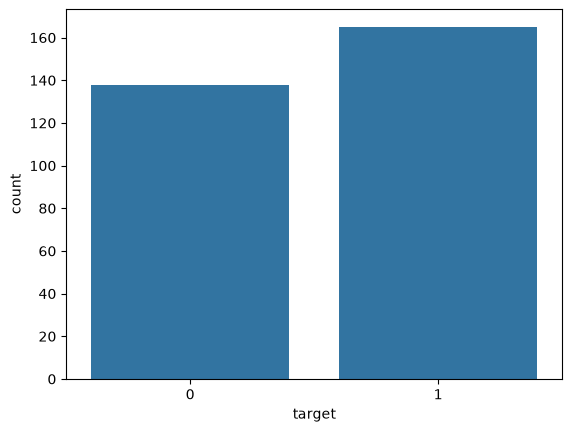

target
1    165
0    138
Name: count, dtype: int64
Percentage of patience without heart problems: 45.54
Percentage of patience with heart problems: 54.46


In [8]:
y = dataset["target"]
sns.countplot(x=y)
plt.show()
target_temp = dataset.target.value_counts()
print(target_temp)

print("Percentage of patience without heart problems: "+str(round(target_temp[0]*100/303,2)))
print("Percentage of patience with heart problems: "+str(round(target_temp[1]*100/303,2)))


Next, We will analyse 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca' and 'thal' features

Analysing the 'Sex' feature

In [12]:
print(dataset["sex"].unique())   

[1 0]


The 'sex' feature has 2 unique features

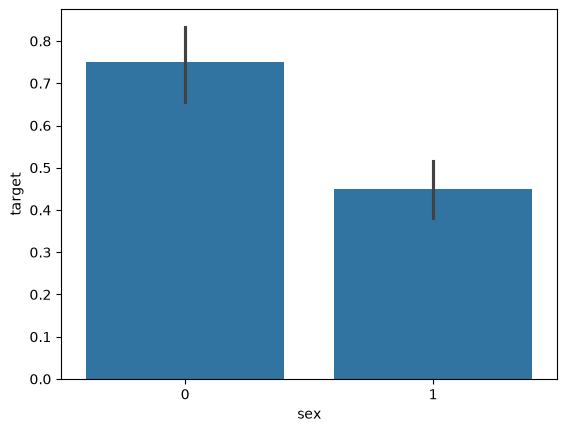

In [11]:
sns.barplot(x=dataset["sex"],y=y)              
plt.show()

The chest pain of '0', i.e. the ones with typical angina are much less likely to have heart problem

Analysing the FBS feature

In [15]:
print(dataset["fbs"].describe())

count    303.000000
mean       0.148515
std        0.356198
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: fbs, dtype: float64


In [16]:
print(dataset["fbs"].unique())

[1 0]


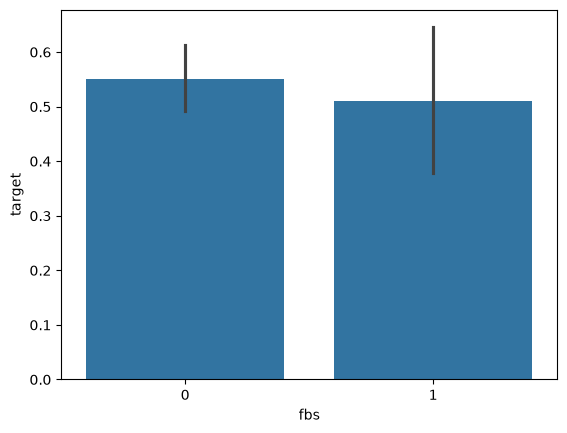

In [17]:
sns.barplot(x=dataset["fbs"],y=y)
plt.show()

Both are nearly the same. Nothing extraordinary here

Analysing the restecg feature

In [18]:
print(dataset["restecg"].unique())

[0 1 2]


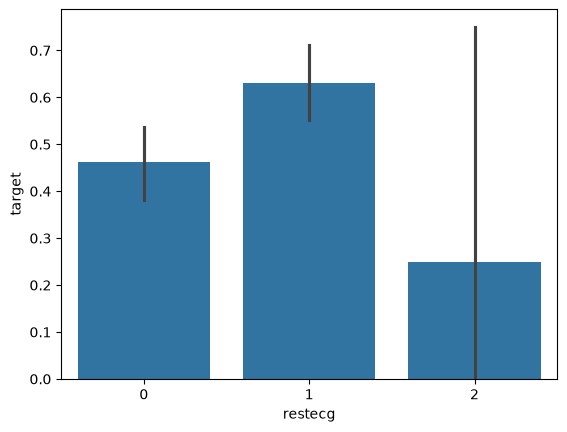

In [19]:
sns.barplot(x=dataset["restecg"],y=y)             
plt.show()

  We realize that people with restecg '1' and '0' are much more likely to have a heart disease than with restecg '2'

Analysing the 'exang' feature

In [20]:
print(dataset["exang"].unique())

[0 1]


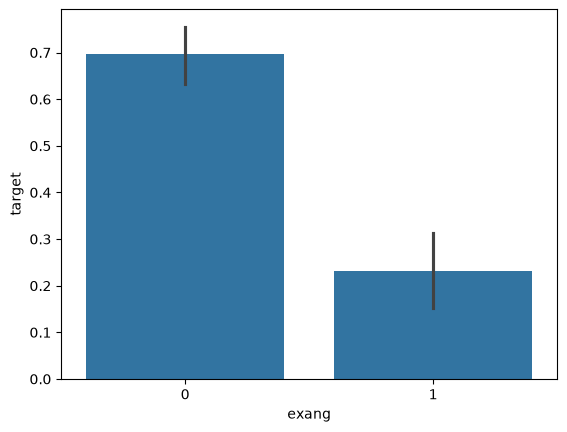

In [21]:
sns.barplot(x=dataset["exang"],y=y)                 
plt.show()

People with exang=1 i.e. Exercise induced angina are much less likely to have heart problems

Analysing the Slope feature

In [22]:
print(dataset["slope"].unique())

[0 2 1]


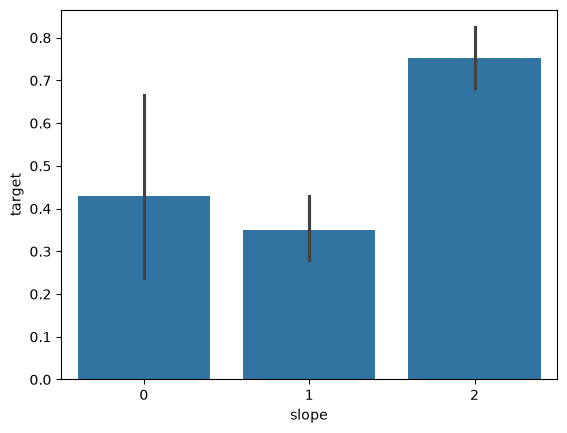

In [23]:
sns.barplot(x=dataset["slope"],y=y)                 
plt.show()

We observe, that Slope '2' causes heart pain much more than Slope '0' and '1'

Analysing the 'ca' feature

In [24]:
print(dataset["ca"].unique())

[0 2 1 3 4]


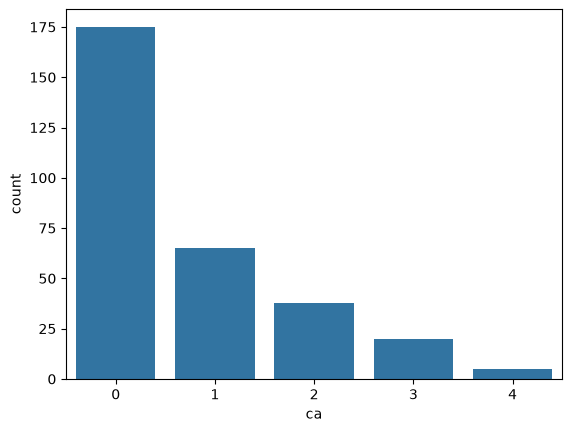

In [25]:
sns.countplot(x=dataset["ca"])               
plt.show()

Distribution of the 'ca' feature

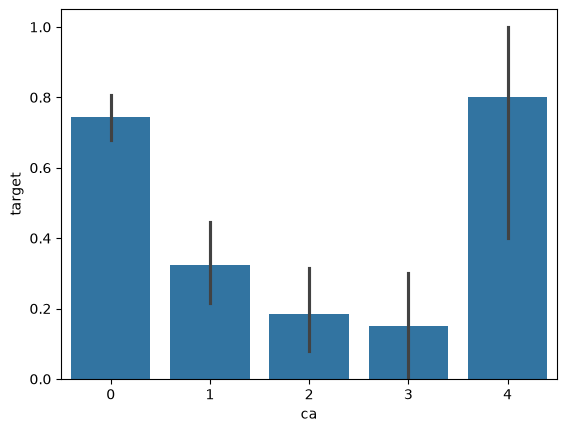

In [26]:
sns.barplot(x=dataset["ca"],y=y)            
plt.show()

Relationship between 'ca' and the target variable
ca=4 has large number of heart patients

Analysing the 'thal' feature

In [27]:
print(dataset["thal"].unique())

[1 2 3 0]


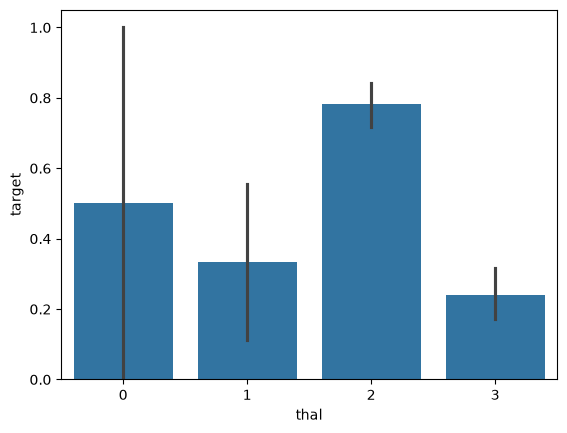

In [29]:
sns.barplot(x=dataset["thal"],y=y)
plt.show()

thal=2 has the highest heart disease rate comparing to others

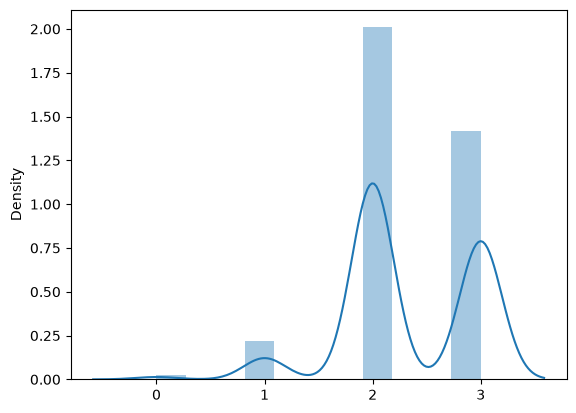

In [30]:
sns.distplot(x=dataset["thal"])
plt.show()

thal=2 and 3 are the most common values in the dataset, while 0 and 1 are rare

Step - 5 Split the dataset into training and testing sets

Train Test Split

In [35]:
from sklearn.model_selection import train_test_split

predictors = dataset.drop("target",axis=1)
target = dataset["target"]

X_train,X_test,Y_train,Y_test = train_test_split(predictors,target,test_size=0.20,random_state=0)
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(242, 13)
(61, 13)
(242,)
(61,)


Step -6 Train machine learning classification models - Model Fitting

In [36]:
from sklearn.metrics import accuracy_score

Logistic Regression Algorithm

In [37]:

from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train,Y_train)
Y_pred_lr = lr.predict(X_test)
print(Y_pred_lr.shape)
score_lr = round(accuracy_score(Y_pred_lr,Y_test)*100,2)
print("The accuracy score achieved using Logistic Regression is: "+str(score_lr)+" %")

(61,)
The accuracy score achieved using Logistic Regression is: 85.25 %


Naive Bayes Algorithm

In [38]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train,Y_train)
Y_pred_nb = nb.predict(X_test)
print(Y_pred_nb.shape)
score_nb = round(accuracy_score(Y_pred_nb,Y_test)*100,2)
print("The accuracy score achieved using Naive Bayes is: "+str(score_nb)+" %")

(61,)
The accuracy score achieved using Naive Bayes is: 85.25 %


Support Vector Machine Algorithm

In [39]:
from sklearn import svm
sv = svm.SVC(kernel='linear')
sv.fit(X_train, Y_train)
Y_pred_svm = sv.predict(X_test)
print(Y_pred_svm.shape)
score_svm = round(accuracy_score(Y_pred_svm,Y_test)*100,2)
print("The accuracy score achieved using Linear SVM is: "+str(score_svm)+" %")

(61,)
The accuracy score achieved using Linear SVM is: 81.97 %


K Nearest Neighbors Algorithm

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train,Y_train)
Y_pred_knn=knn.predict(X_test)
print(Y_pred_knn.shape)
score_knn = round(accuracy_score(Y_pred_knn,Y_test)*100,2)
print("The accuracy score achieved using KNN is: "+str(score_knn)+" %")

(61,)
The accuracy score achieved using KNN is: 67.21 %


Decision Tree Algorithm

In [41]:
from sklearn.tree import DecisionTreeClassifier
max_accuracy = 0
for x in range(200):
    dt = DecisionTreeClassifier(random_state=x)
    dt.fit(X_train, Y_train)
    Y_pred_dt = dt.predict(X_test)
    current_accuracy = round(accuracy_score(Y_pred_dt, Y_test) * 100, 2)
    if (current_accuracy > max_accuracy):
        max_accuracy = current_accuracy
        best_x = x
dt = DecisionTreeClassifier(random_state=best_x)
dt.fit(X_train, Y_train)
Y_pred_dt = dt.predict(X_test)
print(Y_pred_dt.shape)
score_dt = round(accuracy_score(Y_pred_dt,Y_test)*100,2)

print("The accuracy score achieved using Decision Tree is: "+str(score_dt)+" %")

(61,)
The accuracy score achieved using Decision Tree is: 81.97 %


Random Forest Algorithm

In [42]:
from sklearn.ensemble import RandomForestClassifier
max_accuracy = 0
for x in range(200):
    rf = RandomForestClassifier(random_state=x)
    rf.fit(X_train, Y_train)
    Y_pred_rf = rf.predict(X_test)
    current_accuracy = round(accuracy_score(Y_pred_rf, Y_test) * 100, 2)
    if (current_accuracy > max_accuracy):
        max_accuracy = current_accuracy
        best_x = x

rf = RandomForestClassifier(random_state=best_x)
rf.fit(X_train, Y_train)
Y_pred_rf = rf.predict(X_test)
print(Y_pred_rf.shape)

score_rf = round(accuracy_score(Y_pred_rf,Y_test)*100,2)
print("The accuracy score achieved using Random Forest is: "+str(score_rf)+" %")

(61,)
The accuracy score achieved using Random Forest is: 88.52 %


XGBoost Algorithm

In [43]:
import xgboost as xgb
xgb_model = xgb.XGBClassifier(objective="binary:logistic", random_state=42)
xgb_model.fit(X_train, Y_train)
Y_pred_xgb = xgb_model.predict(X_test)
print(Y_pred_xgb.shape)
score_xgb = round(accuracy_score(Y_pred_xgb,Y_test)*100,2)
print("The accuracy score achieved using XGBoost is: "+str(score_xgb)+" %")

(61,)
The accuracy score achieved using XGBoost is: 83.61 %


Step - 7 Evaluate and compare model accuracy

In [44]:
scores = [score_lr,score_nb,score_svm,score_knn,score_dt,score_rf,score_xgb]
algorithms = ["Logistic Regression","Naive Bayes","Support Vector Machine","K-Nearest Neighbors","Decision Tree","Random Forest","XGBoost"]

for i in range(len(algorithms)):
    print("The accuracy score achieved using "+algorithms[i]+" is: "+str(scores[i])+" %")

The accuracy score achieved using Logistic Regression is: 85.25 %
The accuracy score achieved using Naive Bayes is: 85.25 %
The accuracy score achieved using Support Vector Machine is: 81.97 %
The accuracy score achieved using K-Nearest Neighbors is: 67.21 %
The accuracy score achieved using Decision Tree is: 81.97 %
The accuracy score achieved using Random Forest is: 88.52 %
The accuracy score achieved using XGBoost is: 83.61 %


Step - 8 Visualizing algorithm performance

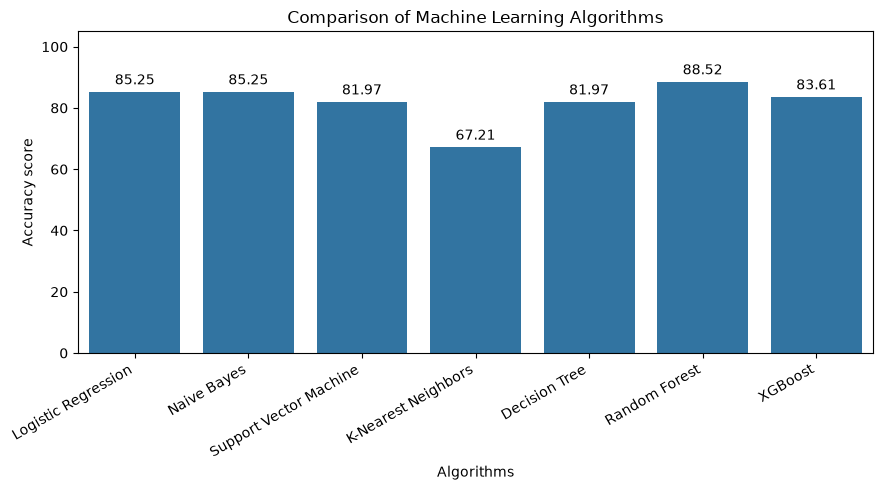

In [48]:
plt.figure(figsize=(9, 5))
ax=sns.barplot(x=algorithms, y=scores)
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.2f')
plt.xlabel("Algorithms")
plt.ylabel("Accuracy score")
plt.title("Comparison of Machine Learning Algorithms")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()